# La película: presión sobre el mercado laboral en Argentina, 2017–2026

En el primer post miré la foto del mercado laboral en el primer trimestre de 2026. En Gran Córdoba, 39 de cada 100 personas en el mercado laboral estaban buscando empleo. La pregunta siguiente era si siempre fue así. En este notebook armo la película, del primer trimestre de 2017 al de 2026, para ver cómo cambió la búsqueda de empleo en el país, en las regiones y en Córdoba.

**Fuente:** EPH-INDEC, base individual, primer trimestre de cada año, 2017 a 2026.

**Indicador:** presión = (desocupados + ocupados que buscan otro empleo) / PEA. Ponderado con `PONDERA`.

## 1. Datos

Uso la base individual de la EPH del primer trimestre de cada año, de 2017 a 2026, que se descarga desde la página de bases de datos del INDEC (https://www.indec.gob.ar/Institucional/Indec/BasesDeDatos). Arranco en 2017 porque, después de la emergencia estadística, la serie se retomó a mediados de 2016. Para correr el notebook hay que descomprimir las diez bases dentro de una carpeta `datos/`, al lado de este archivo (pueden quedar en subcarpetas).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CARPETA_DATOS = Path("datos")

In [2]:
# Leo todas las bases individuales que haya en datos/ (y subcarpetas)
bases = {}
for ruta in sorted(CARPETA_DATOS.rglob("usu_individual_*.txt")):
    df = pd.read_csv(ruta, sep=";", decimal=",", encoding="latin-1",
                     dtype={"PP04D_COD": str}, low_memory=False)
    bases[int(df["ANO4"].iloc[0])] = df

bases = dict(sorted(bases.items()))
{anio: df.shape for anio, df in bases.items()}

{2017: (58675, 177),
 2018: (57951, 177),
 2019: (59369, 177),
 2020: (51643, 177),
 2021: (46693, 177),
 2022: (49706, 177),
 2023: (48638, 177),
 2024: (46050, 235),
 2025: (45425, 235),
 2026: (43739, 234)}

In [3]:
eph = pd.concat(bases.values(), ignore_index=True)
eph.shape

(507889, 239)

## 2. Análisis exploratorio

*Control de calidad de las bases antes de calcular indicadores*

Antes de realizar cualquier calculo, revisé que las diez bases fueran comparables. Si en algún año cambia una variable o un código, la serie puede mostrar un salto que no existe en la realidad. Los controles van de lo más básico a lo más fino.

### 2.1 ¿Las variables están en todos los años?

In [4]:
presencia = pd.DataFrame({anio: eph.columns.isin(df.columns) for anio, df in bases.items()},
                         index=eph.columns)
presencia[~presencia.all(axis=1)]

,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
CAT_INAC,True,True,True,True,True,True,True,True,True,False
V2_M,True,True,True,True,True,True,True,False,False,False
V5_M,True,True,True,True,True,True,True,False,False,False
V11_M,True,True,True,True,True,True,True,False,False,False
V21_M,True,True,True,True,True,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...
P_RDECCF,False,False,False,False,False,False,False,True,True,True
P_GDECCF,False,False,False,False,False,False,False,True,True,True
P_PDECCF,False,False,False,False,False,False,False,True,True,True
P_IDECCF,False,False,False,False,False,False,False,True,True,True


In [5]:
presencia.loc[["EMPLEO", "SECTOR", "PP02A", "PP03K"]]

,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
EMPLEO,False,False,False,False,False,False,False,True,True,True
SECTOR,False,False,False,False,False,False,False,True,True,True
PP02A,False,False,False,False,False,False,False,True,True,True
PP03K,False,False,False,False,False,False,False,True,True,True


In [6]:
claves = ["ANO4", "TRIMESTRE", "REGION", "AGLOMERADO", "PONDERA", "ESTADO", "PP03J"]
[v for v in claves if not presencia.loc[v].all()]   # lista vacía = todas están en los 10 años

[]

Hay 67 variables que no están en todos los años. La mayoría corresponde a la actualización del cuestionario que hizo el INDEC en 2024: desde ese año aparecen variables nuevas como EMPLEO (informalidad), SECTOR o PP03K (para qué busca otro empleo) y cambian las de ingresos. Las siete variables que uso en este análisis están en los diez años.

### 2.2 Año, trimestre y tamaño de muestra

In [7]:
pd.crosstab(eph["ANO4"], eph["TRIMESTRE"])

TRIMESTRE,1
ANO4,
2017,58675
2018,57951
2019,59369
2020,51643
2021,46693
2022,49706
2023,48638
2024,46050
2025,45425


Las diez bases son del primer trimestre. La muestra baja de 58.675 personas en 2017 a 43.739 en 2026, un 25% menos, con caídas fuertes en 2020 y 2021 por el operativo en pandemia. Menos casos significa más margen de error, así que las diferencias chicas entre años hay que tomarlas con cuidado.

### 2.3 Códigos de ESTADO

In [8]:
pd.crosstab(eph["ANO4"], eph["ESTADO"])

ESTADO,0,1,2,3,4
ANO4,,,,,
2017,55,23515,1827,24588,8690
2018,71,23995,1927,23565,8393
2019,111,24196,2364,24173,8525
2020,97,21139,2011,21093,7303
2021,74,19014,1766,19684,6155
2022,68,21221,1367,20615,6435
2023,56,21518,1322,19426,6316
2024,81,20325,1362,18724,5558
2025,75,20076,1381,18866,5027


ESTADO usa los mismos cinco códigos en los diez años (0 sin entrevista, 1 ocupado, 2 desocupado, 3 inactivo, 4 menor de 10 años), así que es comparable en toda la serie. Hay pocos desocupados en la muestra, entre 1.300 y 2.400 por año en todo el país, por eso la desocupación de una sola ciudad es poco precisa. La presión, que se calcula sobre toda la PEA, es más estable.

### 2.4 Aglomerados y regiones

In [9]:
nombres_aglo = {
    2: "Gran La Plata", 3: "Bahía Blanca-Cerri", 4: "Gran Rosario", 5: "Gran Santa Fe",
    6: "Gran Paraná", 7: "Posadas", 8: "Gran Resistencia", 9: "Comodoro Rivadavia-Rada Tilly",
    10: "Gran Mendoza", 12: "Corrientes", 13: "Gran Córdoba", 14: "Concordia",
    15: "Formosa", 17: "Neuquén-Plottier", 18: "Santiago del Estero-La Banda", 19: "Jujuy-Palpalá",
    20: "Río Gallegos", 22: "Gran Catamarca", 23: "Gran Salta", 25: "La Rioja",
    26: "Gran San Luis", 27: "Gran San Juan", 29: "Gran Tucumán-Tafí Viejo", 30: "Santa Rosa-Toay",
    31: "Ushuaia-Río Grande", 32: "CABA", 33: "Partidos del GBA", 34: "Mar del Plata",
    36: "Río Cuarto", 38: "San Nicolás-Villa Constitución", 91: "Rawson-Trelew",
    93: "Viedma-Carmen de Patagones",
}
nombres_region = {1: "Gran Buenos Aires", 40: "Noroeste", 41: "Noreste",
                  42: "Cuyo", 43: "Pampeana", 44: "Patagonia"}

eph.groupby("ANO4")["AGLOMERADO"].nunique()

ANO4
2017    32
2018    32
2019    32
2020    32
2021    32
2022    32
2023    32
2024    32
2025    32
2026    32
Name: AGLOMERADO, dtype: int64

In [10]:
# PEA encuestada (sin ponderar) por aglomerado: define qué tan preciso es cada uno
pea_casos = eph[eph["ESTADO"].isin([1, 2])]
n_aglo = pd.crosstab(pea_casos["AGLOMERADO"], pea_casos["ANO4"])
n_aglo.index = n_aglo.index.map(nombres_aglo)
n_aglo["Mínimo"] = n_aglo.min(axis=1)
n_aglo.sort_values("Mínimo")

ANO4,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Mínimo
AGLOMERADO,,,,,,,,,,,
Santa Rosa-Toay,465,448,456,418,239,386,458,420,434,472,239
Río Gallegos,429,423,449,409,435,385,316,276,304,356,276
Comodoro Rivadavia-Rada Tilly,497,472,428,407,450,405,423,333,348,290,290
Viedma-Carmen de Patagones,445,533,575,389,424,416,428,426,346,341,341
Rawson-Trelew,587,616,656,490,543,575,487,467,382,341,341
Bahía Blanca-Cerri,652,657,602,508,500,479,475,470,355,395,355
Gran Resistencia,429,591,483,540,385,543,566,618,648,617,385
Gran La Plata,582,583,704,626,578,580,627,535,458,387,387
Ushuaia-Río Grande,498,437,488,388,458,476,413,421,509,485,388


In [11]:
n_region = pd.crosstab(pea_casos["REGION"], pea_casos["ANO4"])
n_region.index = n_region.index.map(nombres_region)
n_region

ANO4,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
REGION,,,,,,,,,,
Gran Buenos Aires,5156,5052,5014,4035,1950,3213,3809,3535,3719,3517
Noroeste,5378,5447,5546,4938,5069,4974,4757,4519,4576,4568
Noreste,2173,2306,2190,2082,2036,2146,2262,2238,2058,2104
Cuyo,2202,2354,2573,2430,2468,2521,2444,2118,2188,1982
Pampeana,7519,7802,8171,7140,6463,6918,6899,6755,6471,6501
Patagonia,2914,2961,3066,2525,2794,2816,2669,2522,2445,2324


Los diez años tienen los mismos 32 aglomerados, así que la cobertura geográfica no cambia. Pero el tamaño de muestra es muy distinto entre ellos: en su peor año, la mitad de los aglomerados tiene menos de 520 personas activas encuestadas, con márgenes de error de ±4 a ±6 puntos. Por eso comparo por regiones, que tienen alrededor de 2.000 casos o más todos los años. Gran Córdoba es la excepción: tiene entre 1.000 y 1.200 casos por año (816 en 2021), suficiente para mirarla sola con un margen de unos ±4 puntos.

### 2.5 La pregunta clave: PP03J (¿buscó otro empleo?)

In [12]:
ocup = eph[eph["ESTADO"] == 1].copy()
pd.crosstab(ocup["ANO4"], ocup["PP03J"], dropna=False)

PP03J,1.0,2.0,9.0
ANO4,,,
2017,3039,20422,54
2018,3560,20409,26
2019,4368,19795,33
2020,4191,16925,23
2021,3360,15633,21
2022,3424,17779,18
2023,3430,18056,32
2024,3172,17116,37
2025,3093,16941,42


In [13]:
def pct_busca(d):
    return d.loc[d["PP03J"] == 1, "PONDERA"].sum() / d["PONDERA"].sum() * 100

ocup["GBA"] = ocup["AGLOMERADO"].isin([32, 33])
pd.DataFrame({
    "Total": ocup.groupby("ANO4")[["PP03J", "PONDERA"]].apply(pct_busca),
    "GBA": ocup[ocup["GBA"]].groupby("ANO4")[["PP03J", "PONDERA"]].apply(pct_busca),
    "Resto del país": ocup[~ocup["GBA"]].groupby("ANO4")[["PP03J", "PONDERA"]].apply(pct_busca),
}).round(1)

,Total,GBA,Resto del país
ANO4,,,
2017,15.5,16.9,13.7
2018,16.8,17.7,15.7
2019,19.4,19.8,19.0
2020,19.9,18.4,21.8
2021,18.4,17.5,19.4
2022,16.7,15.7,17.9
2023,15.9,14.4,17.7
2024,17.3,17.0,17.7
2025,17.5,18.2,16.7


PP03J es la pregunta "¿estuvo buscando otro empleo?" y es la mitad de la presión. Tiene los mismos códigos en los diez años y no hay ocupados sin respuesta. Entre 2023 y 2024, el año del cambio de cuestionario, el porcentaje que busca sube 1,4 puntos. Revisé de dónde venía: la suba está toda dentro del Gran Buenos Aires (de 14,4% a 17,0%), mientras que en el resto del país, con el mismo cuestionario nuevo, no se mueve (17,7% en los dos años). Si fuera un efecto del cuestionario se vería en todo el país, así que lo tomo como variación de la muestra y no como un quiebre de la serie.

### 2.6 Validación contra el INDEC

In [14]:
def tasas(d):
    poblacion = d["PONDERA"].sum()
    ocupados = d.loc[d["ESTADO"] == 1, "PONDERA"].sum()
    desocupados = d.loc[d["ESTADO"] == 2, "PONDERA"].sum()
    pea = ocupados + desocupados
    return pd.Series({"Actividad (%)": pea / poblacion * 100,
                      "Empleo (%)": ocupados / poblacion * 100,
                      "Desocupación (%)": desocupados / pea * 100})

eph.groupby("ANO4")[["ESTADO", "PONDERA"]].apply(tasas).round(1)

,Actividad (%),Empleo (%),Desocupación (%)
ANO4,,,
2017,45.5,41.3,9.2
2018,46.7,42.4,9.1
2019,47.0,42.3,10.1
2020,47.1,42.2,10.4
2021,46.3,41.6,10.2
2022,46.5,43.3,7.0
2023,48.3,45.0,6.9
2024,48.0,44.3,7.7
2025,48.2,44.4,7.9


Calculé las tres tasas básicas y las comparé con las que publica el INDEC en su informe de mercado de trabajo del primer trimestre de cada año. Coinciden en los diez años (por ejemplo, la desocupación da 9,2% en 2017 y 7,8% en 2026), así que la forma de procesar las bases es correcta y puedo confiar en lo que calculo después.

## 3. El indicador

La desocupación solo cuenta a quienes no tienen trabajo y lo están buscando. Pero quien se postula a un aviso compite también con personas que ya trabajan y buscan otro empleo. Por eso miro la presión sobre el mercado laboral: suma desocupados y ocupados que buscan otro empleo, sobre el total de personas en el mercado laboral (PEA). El INDEC publica un indicador de presión más amplio, que además incluye a quienes trabajan y estarían disponibles para trabajar más aunque no estén buscando. Acá uso solo la parte activa: las personas que efectivamente salieron a buscar.

Cada valor tiene un margen de error. Lo calculo al 95% de confianza y lo multiplico por 1,3 (efecto de diseño), porque la EPH no es una muestra al azar simple: se encuesta por viviendas y zonas, y eso agranda el error. Cuando comparo dos valores, considero que la diferencia es real solo si supera el margen combinado de los dos.

In [15]:
VARS = ["ESTADO", "PP03J", "PONDERA"]   # columnas que usa la función

def presion(d):
    pea_casos = d[d["ESTADO"].isin([1, 2])]
    pea = pea_casos["PONDERA"].sum()
    desocupados = d.loc[d["ESTADO"] == 2, "PONDERA"].sum()
    buscan = d.loc[(d["ESTADO"] == 1) & (d["PP03J"] == 1), "PONDERA"].sum()
    p = (desocupados + buscan) / pea
    n = len(pea_casos)
    return pd.Series({
        "Desocupados (% PEA)": desocupados / pea * 100,
        "Buscan otro empleo (% PEA)": buscan / pea * 100,
        "Presión (%)": p * 100,
        "n (PEA)": n,
        # margen al 95%, con efecto de diseño de 1,3 por ser una muestra por conglomerados
        "Margen ± (pp)": 1.96 * np.sqrt(p * (1 - p) / n) * 1.3 * 100,
    })

## 4. Resultados

### 4.1 Total país, año por año

In [16]:
pais = eph.groupby("ANO4")[VARS].apply(presion).round(1)
pais

,Desocupados (% PEA),Buscan otro empleo (% PEA),Presión (%),n (PEA),Margen ± (pp)
ANO4,,,,,
2017,9.2,14.1,23.3,25342.0,0.7
2018,9.1,15.3,24.4,25922.0,0.7
2019,10.1,17.5,27.6,26560.0,0.7
2020,10.4,17.9,28.2,23150.0,0.8
2021,10.2,16.5,26.7,20780.0,0.8
2022,7.0,15.5,22.5,22588.0,0.7
2023,6.9,14.8,21.7,22840.0,0.7
2024,7.7,16.0,23.7,21687.0,0.7
2025,7.9,16.1,24.0,21457.0,0.7


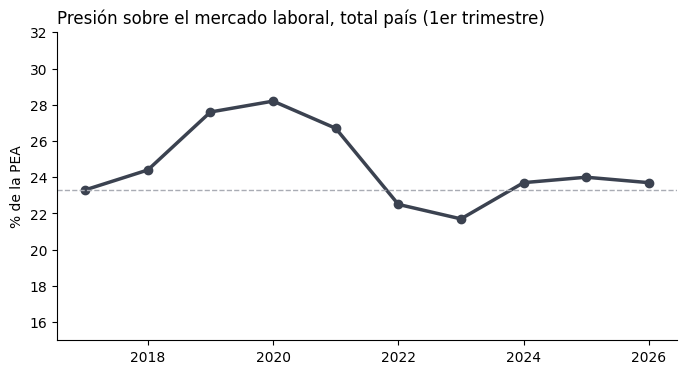

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pais.index, pais["Presión (%)"], color="#3B4250", linewidth=2.5, marker="o")
ax.axhline(pais.loc[2017, "Presión (%)"], color="#A9ACB4", linestyle="--", linewidth=1)
ax.set_title("Presión sobre el mercado laboral, total país (1er trimestre)", loc="left")
ax.set_ylabel("% de la PEA")
ax.set_ylim(15, 32)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

El total país hizo un ciclo completo. Entre 2017 y 2020 la presión subió de 23,3% a 28,2%, se mantuvo alta en la pandemia y después bajó, hasta 21,7% en 2023, por debajo del punto de partida. En 2026 está en 23,7%, casi el mismo nivel que en 2017.

### 4.2 Quién busca: desocupados y ocupados que buscan otro empleo, por período

In [18]:
periodos = {
    "Punto de partida (2017)": [2017],
    "2018-2020": [2018, 2019, 2020],
    "Pandemia (2021)": [2021],
    "2022-2023": [2022, 2023],
    "Hoy (2024-2026)": [2024, 2025, 2026],
}
cols = ["Desocupados (% PEA)", "Buscan otro empleo (% PEA)", "Presión (%)"]
por_periodo = pd.DataFrame({p: pais.loc[a, cols].mean() for p, a in periodos.items()}).T.round(1)
por_periodo

,Desocupados (% PEA),Buscan otro empleo (% PEA),Presión (%)
Punto de partida (2017),9.2,14.1,23.3
2018-2020,9.9,16.9,26.7
Pandemia (2021),10.2,16.5,26.7
2022-2023,7.0,15.2,22.1
Hoy (2024-2026),7.8,16.0,23.8


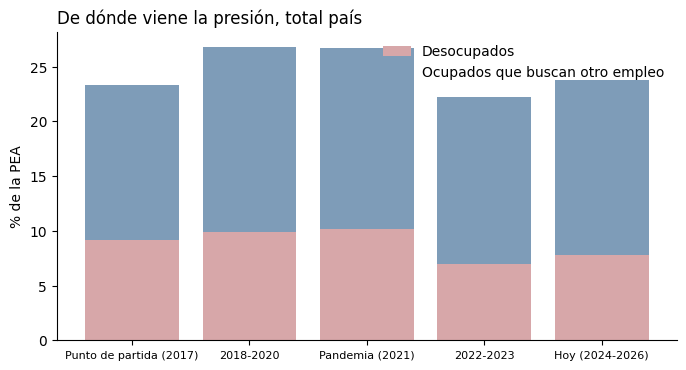

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(por_periodo.index, por_periodo["Desocupados (% PEA)"], color="#D7A7A9", label="Desocupados")
ax.bar(por_periodo.index, por_periodo["Buscan otro empleo (% PEA)"],
       bottom=por_periodo["Desocupados (% PEA)"], color="#7E9CB8", label="Ocupados que buscan otro empleo")
ax.set_title("De dónde viene la presión, total país", loc="left")
ax.set_ylabel("% de la PEA")
ax.legend(frameon=False)
ax.tick_params(axis="x", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [20]:
# De cada 100 personas que buscan trabajo, cuántas ya tienen empleo
(pais["Buscan otro empleo (% PEA)"] / pais["Presión (%)"] * 100).round(0)

ANO4
2017    61.0
2018    63.0
2019    63.0
2020    63.0
2021    62.0
2022    69.0
2023    68.0
2024    68.0
2025    67.0
2026    67.0
dtype: float64

El total casi no cambió, pero sí de dónde viene la presión. Hoy hay menos desocupados que en 2017 (7,8% contra 9,2%) y más ocupados que buscan otro empleo (16,0% contra 14,1%). En 2017, 61 de cada 100 personas que buscaban trabajo ya tenían uno. Desde 2022 son entre 67 y 69 de cada 100.

### 4.3 Regiones: hoy contra 2017

In [21]:
por_region = eph.groupby(["REGION", "ANO4"])[VARS].apply(presion)
pres = por_region["Presión (%)"].unstack()
margen = por_region["Margen ± (pp)"].unstack()

hoy = [2024, 2025, 2026]
regiones = pd.DataFrame({
    "2017": pres[2017],
    "Hoy (prom. 2024-2026)": pres[hoy].mean(axis=1),
})
regiones["Cambio"] = regiones["Hoy (prom. 2024-2026)"] - regiones["2017"]
# margen de la diferencia: combino el de 2017 con el del promedio de tres años
margen_hoy = np.sqrt((margen[hoy] ** 2).sum(axis=1)) / 3
regiones["Margen del cambio ±"] = np.sqrt(margen[2017] ** 2 + margen_hoy ** 2)
regiones["Suba significativa"] = regiones["Cambio"] > regiones["Margen del cambio ±"]
regiones.index = regiones.index.map(nombres_region)
regiones.sort_values("Hoy (prom. 2024-2026)", ascending=False).round(1)

,2017,Hoy (prom. 2024-2026),Cambio,Margen del cambio ±,Suba significativa
REGION,,,,,
Pampeana,22.8,25.3,2.5,1.5,True
Gran Buenos Aires,26.0,24.5,-1.4,1.9,False
Noroeste,22.6,24.0,1.4,1.7,False
Cuyo,15.6,23.6,8.0,2.4,True
Noreste,9.1,15.0,5.8,1.9,True
Patagonia,13.2,14.2,1.0,1.9,False


Comparo el promedio de 2024–2026 con 2017, uso el promedio de los tres últimos años para tener un valor más estable. Tres regiones tienen hoy más presión que en 2017, con una suba mayor al margen de error: Cuyo (+8,0 puntos), Noreste (+5,8) y Pampeana (+2,5). En el Gran Buenos Aires, el Noroeste y la Patagonia la presión volvió a valores parecidos a los de 2017.

### 4.4 La región Pampeana con y sin Gran Córdoba

In [22]:
cordoba = eph[eph["AGLOMERADO"] == 13]
pampeana_sin_cba = eph[(eph["REGION"] == 43) & (eph["AGLOMERADO"] != 13)]

comparacion = pd.DataFrame({
    "Gran Córdoba": cordoba.groupby("ANO4")[VARS].apply(presion)["Presión (%)"],
    "Margen Córdoba ±": cordoba.groupby("ANO4")[VARS].apply(presion)["Margen ± (pp)"],
    "Resto de la Pampeana": pampeana_sin_cba.groupby("ANO4")[VARS].apply(presion)["Presión (%)"],
    "Total país": pais["Presión (%)"],
}).round(1)
comparacion

,Gran Córdoba,Margen Córdoba ±,Resto de la Pampeana,Total país
ANO4,,,,
2017,28.2,3.5,20.9,23.3
2018,30.6,3.4,21.2,24.4
2019,35.4,3.5,24.4,27.6
2020,42.1,4.0,25.0,28.2
2021,40.9,4.4,21.8,26.7
2022,36.6,3.8,17.4,22.5
2023,35.3,3.7,19.0,21.7
2024,39.7,3.8,19.3,23.7
2025,39.1,3.8,19.0,24.0


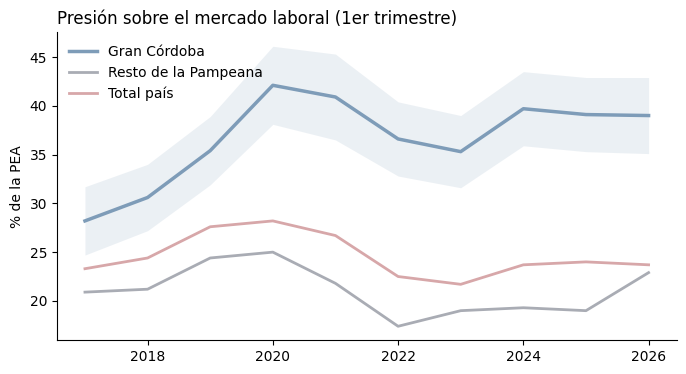

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(comparacion.index,
                comparacion["Gran Córdoba"] - comparacion["Margen Córdoba ±"],
                comparacion["Gran Córdoba"] + comparacion["Margen Córdoba ±"],
                color="#7E9CB8", alpha=0.15, linewidth=0)
ax.plot(comparacion.index, comparacion["Gran Córdoba"], color="#7E9CB8", linewidth=2.5, label="Gran Córdoba")
ax.plot(comparacion.index, comparacion["Resto de la Pampeana"], color="#A9ACB4", linewidth=2, label="Resto de la Pampeana")
ax.plot(comparacion.index, comparacion["Total país"], color="#D7A7A9", linewidth=2, label="Total país")
ax.set_title("Presión sobre el mercado laboral (1er trimestre)", loc="left")
ax.set_ylabel("% de la PEA")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Dentro de la región Pampeana, la suba se explica por Gran Córdoba. Su presión pasó de 28,2% en 2017 a 39,0% en 2026, una suba mayor que su margen de error, mientras que el resto de la región está en niveles parecidos a los de 2017. Qué hay detrás de ese aumento es el tema del próximo notebook.

## 5. Limitaciones

- **Es una encuesta por muestra.** Cada número tiene un margen de error, que es más grande cuanto más chico es el grupo. Además, la muestra se achicó un 25% entre 2017 y 2026, así que los años recientes son un poco menos precisos.
- **Comparo solo el primer trimestre de cada año.** Lo hago para no mezclar estaciones, porque el empleo cambia a lo largo del año. El último trimestre con microdatos publicados es el primero de 2026; el segundo ya salió en los informes del INDEC, pero todavía no en las bases.
- **2020 y 2021 tienen un contexto especial.** El operativo de la encuesta estuvo afectado por la pandemia. El primer trimestre de 2020 es casi en su totalidad anterior a la cuarentena.
- **Trabajo por regiones y no por ciudad.** La mayoría de los aglomerados tiene muestras chicas, con márgenes de error de ±4 a ±6 puntos. Gran Córdoba es la excepción, porque tiene una de las muestras más grandes del interior.
- **Mi indicador es la parte activa de la presión.** El INDEC publica uno más amplio, que suma a quienes trabajan y estarían disponibles para más horas aunque no busquen. Por eso mis valores dan más bajos que los oficiales.

**Lo que sigue**

Este análisis deja una pregunta abierta: ¿por qué en Gran Córdoba la presión subió de 28 a 39 y no volvió a bajar, mientras el resto de la región está como en 2017? En el próximo notebook miro qué hay detrás: de dónde viene esa suba, cómo es el trabajo de quienes buscan otro empleo (cuántas horas trabajan, si están registrados) y si pasa lo mismo en otras ciudades del país.